# 05 - Final evaluation on the held-out test set

This notebook evaluates the Linear SVM, Random Forest and CNN on the official held-out test split. The selected model is determined using validation macro-F1 from notebooks 03 and 04. Test metrics provide the final estimate of model performance and are not used for further tuning.

**Notebooks 01 to 04 must be completed first.** The classical and CNN training notebooks should use the same 12 classes, including `silence`, before the final evaluation is run.

## 1. Imports and paths

In [1]:
from pathlib import Path
import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import ConfusionMatrixDisplay

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import evaluate_classifier
from src.deep_learning import SmallAudioCNN, SpeechCommandsMelDataset, evaluate_cnn

DATA_DIR = PROJECT_ROOT / 'notebooks' / 'data' / 'processed'
MODEL_DIR = PROJECT_ROOT / 'models'
INDEX_PATH = DATA_DIR / 'audio_index_with_silence.csv'
FEATURE_PATH = DATA_DIR / 'mfcc_features.npz'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

for required_path in [INDEX_PATH, FEATURE_PATH, MODEL_DIR / 'linear_svm.joblib',
                      MODEL_DIR / 'random_forest.joblib', MODEL_DIR / 'small_audio_cnn.pt',
                      MODEL_DIR / 'validation_model_comparison.json',
                      MODEL_DIR / 'cnn_validation_model_comparison.json']:
    if not required_path.is_file():
        raise FileNotFoundError(f'Missing {required_path}. Run corrected notebooks 02-04 first.')

print('Project root:', PROJECT_ROOT)
print('Evaluation device:', DEVICE)

Project root: c:\Users\a\Documents\machine_learning_cycle
Evaluation device: cpu


## 2. Load the untouched test split and verify class alignment

In [2]:
audio_index = pd.read_csv(INDEX_PATH)
test_frame = audio_index[audio_index['split'].astype(str) == 'test'].copy()
with np.load(FEATURE_PATH, allow_pickle=True) as data:
    X_test = data['X_test'].astype(np.float32)
    y_test = np.asarray(data['y_test'], dtype=str)

index_classes = sorted(audio_index['target'].astype(str).unique().tolist())
feature_classes = sorted(np.unique(y_test).tolist())
assert index_classes == feature_classes, (
    f'Class mismatch between audio index and MFCC test features: {index_classes} vs {feature_classes}'
)
assert 'silence' in index_classes and len(index_classes) == 12
print('Test audio clips:', len(test_frame))
print('MFCC test matrix:', X_test.shape)
print('Classes:', index_classes)
display(test_frame['target'].value_counts().sort_index().to_frame('test_examples'))

Test audio clips: 11065
MFCC test matrix: (11065, 80)
Classes: ['down', 'go', 'left', 'no', 'off', 'on', 'right', 'silence', 'stop', 'unknown', 'up', 'yes']


,test_examples
target,
down,406
go,402
left,412
no,405
off,402
on,396
right,396
silence,60
stop,411


## 3. Load validation results and identify the validation-selected model

In [3]:
classical_validation = json.loads((MODEL_DIR / 'validation_model_comparison.json').read_text(encoding='utf-8'))
cnn_validation = json.loads((MODEL_DIR / 'cnn_validation_model_comparison.json').read_text(encoding='utf-8'))
validation_rows = list(classical_validation)
validation_rows.append({'model': 'small_audio_cnn', **cnn_validation})
validation_comparison = pd.DataFrame(validation_rows).sort_values(
    ['macro_f1', 'balanced_accuracy'], ascending=False
).reset_index(drop=True)
display(validation_comparison.round(4))
validation_winner = str(validation_comparison.iloc[0]['model'])
print('Model selected using validation macro-F1:', validation_winner)
print('This selection is fixed before examining test metrics.')

,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,training_seconds,validation_prediction_seconds
0,small_audio_cnn,0.8368,0.9107,0.7348,0.9107,0.8045,NaN,NaN,NaN
1,linear_svm,0.5132,0.5089,0.3648,0.5089,0.4052,0.5367,19.9817,0.2929
2,random_forest,0.6488,0.2019,0.7667,0.2019,0.2229,0.5298,275.2528,2.5762


Model selected using validation macro-F1: small_audio_cnn
This selection is fixed before examining test metrics.


## 4. Evaluate Linear SVM and Random Forest

\nlinear_svm per-class test report


,precision,recall,f1-score,support
down,0.188,0.296,0.229,406.000
go,0.242,0.338,0.282,402.000
left,0.251,0.432,0.318,412.000
no,0.181,0.160,0.170,405.000
off,0.362,0.535,0.432,402.000
on,0.322,0.449,0.375,396.000
right,0.236,0.093,0.134,396.000
silence,0.984,1.000,0.992,60.000
stop,0.335,0.482,0.395,411.000
unknown,0.778,0.589,0.670,6931.000


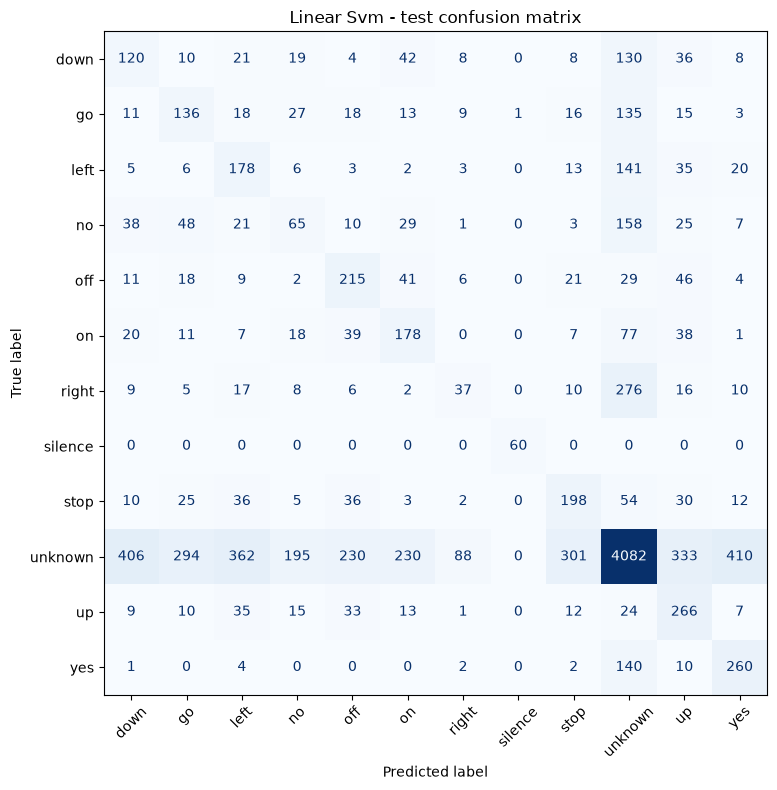

\nrandom_forest per-class test report


,precision,recall,f1-score,support
down,0.000,0.000,0.000,406.000
go,0.000,0.000,0.000,402.000
left,1.000,0.002,0.005,412.000
no,0.000,0.000,0.000,405.000
off,0.725,0.164,0.268,402.000
on,0.889,0.020,0.040,396.000
right,0.000,0.000,0.000,396.000
silence,0.870,1.000,0.930,60.000
stop,0.654,0.041,0.078,411.000
unknown,0.642,0.995,0.780,6931.000


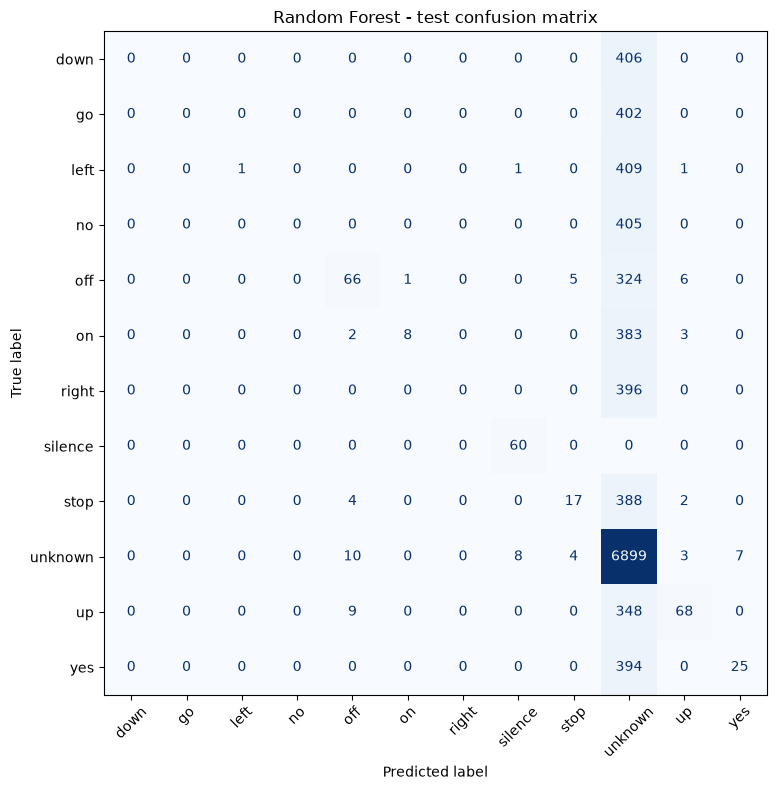

In [4]:
test_results = {}
test_rows = []
for model_name in ['linear_svm', 'random_forest']:
    bundle = joblib.load(MODEL_DIR / f'{model_name}.joblib')
    result = evaluate_classifier(bundle['model'], X_test, y_test)
    test_results[model_name] = result
    test_rows.append({'model': model_name, **result['metrics']})
    print(f'\\n{model_name} per-class test report')
    display(pd.DataFrame(result['report']).T.round(3))
    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(
        confusion_matrix=result['confusion_matrix'], display_labels=result['labels']
    ).plot(ax=ax, xticks_rotation=45, cmap='Blues', colorbar=False)
    ax.set_title(f'{model_name.replace("_", " ").title()} - test confusion matrix')
    plt.tight_layout(); plt.show()

## 5. Evaluate the CNN on the same test recordings

,precision,recall,f1-score,support
down,0.607,0.867,0.714,406.000
go,0.481,0.903,0.627,402.000
left,0.761,0.905,0.827,412.000
no,0.784,0.832,0.807,405.000
off,0.751,0.893,0.816,402.000
on,0.562,0.909,0.695,396.000
right,0.785,0.924,0.849,396.000
silence,0.952,1.000,0.976,60.000
stop,0.817,0.966,0.885,411.000
unknown,0.983,0.799,0.882,6931.000


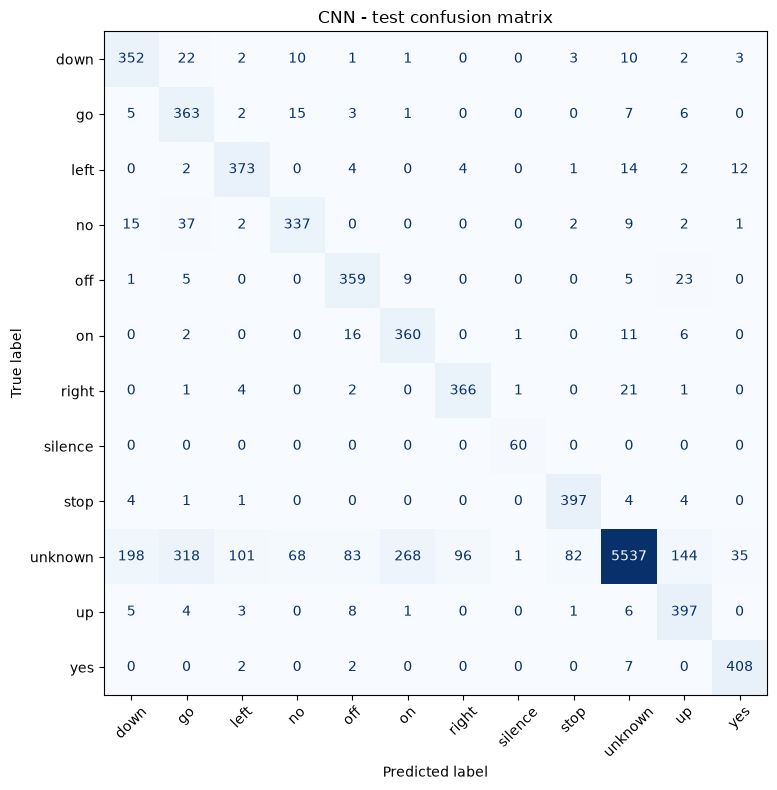

In [5]:
checkpoint = torch.load(MODEL_DIR / 'small_audio_cnn.pt', map_location=DEVICE)
cnn_labels = list(checkpoint['labels'])
assert cnn_labels == index_classes, f'CNN classes do not match the test index: {cnn_labels}'
label_to_id = {label: i for i, label in enumerate(cnn_labels)}
test_dataset = SpeechCommandsMelDataset(test_frame, label_to_id, sample_rate=16_000,
                                        n_mels=int(checkpoint['n_mels']))
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=0)
cnn_model = SmallAudioCNN(n_classes=len(cnn_labels)).to(DEVICE)
cnn_model.load_state_dict(checkpoint['state_dict'])
cnn_result = evaluate_cnn(cnn_model, test_loader, cnn_labels, device=DEVICE)
cnn_metrics = {key: cnn_result[key] for key in [
    'accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1'
]}
test_results['small_audio_cnn'] = {
    'metrics': cnn_metrics,
    'report': cnn_result['report'],
    'confusion_matrix': cnn_result['confusion_matrix'],
    'labels': cnn_labels,
}
test_rows.append({'model': 'small_audio_cnn', **cnn_metrics})
display(pd.DataFrame(cnn_result['report']).T.round(3))
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(confusion_matrix=cnn_result['confusion_matrix'],
                       display_labels=cnn_labels).plot(
    ax=ax, xticks_rotation=45, cmap='Blues', colorbar=False
)
ax.set_title('CNN - test confusion matrix')
plt.tight_layout(); plt.show()

## 6. Compare final test metrics and save the evaluation

In [6]:
test_comparison = pd.DataFrame(test_rows).set_index('model')
display(test_comparison.sort_values('macro_f1', ascending=False).round(4))

print('Validation-selected model:', validation_winner)
print('Its held-out test metrics:')
display(test_comparison.loc[[validation_winner]].round(4))

output_path = MODEL_DIR / 'final_test_metrics.json'
output_path.write_text(json.dumps({
    'validation_selected_model': validation_winner,
    'validation_comparison': validation_rows,
    'test_metrics': test_comparison.reset_index().to_dict(orient='records'),
}, indent=2), encoding='utf-8')
for model_name, result in test_results.items():
    pd.DataFrame(result['report']).T.to_csv(MODEL_DIR / f'{model_name}_test_classification_report.csv')
print('Saved final test metrics:', output_path)
print('Final test evaluation complete. Keep these results fixed for the report.')

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
model,,,,,,
small_audio_cnn,0.8413,0.9089,0.7541,0.9089,0.8160,NaN
linear_svm,0.5237,0.4684,0.3784,0.4684,0.4052,0.5436
random_forest,0.6456,0.2036,0.5316,0.2036,0.2066,0.5225


Validation-selected model: small_audio_cnn
Its held-out test metrics:


,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
model,,,,,,
small_audio_cnn,0.8413,0.9089,0.7541,0.9089,0.816,NaN


Saved final test metrics: c:\Users\a\Documents\machine_learning_cycle\models\final_test_metrics.json
Final test evaluation complete. Keep these results fixed for the report.


## Interpretation of evaluation metrics

- **Accuracy** is the proportion of predictions that are correct. It is interpreted with care because `unknown` has substantially more examples than most command classes.
- **Balanced accuracy** calculates recall for each class and averages the results, giving each class equal weight.
- **Macro precision, recall and F1** give equal importance to all 12 classes. Macro-F1 is the main comparison metric because it combines precision and recall across the classes.
- **Weighted F1** weights each class according to its number of test examples and therefore reflects the original class distribution more strongly.
- **The confusion matrix** shows which commands are misclassified. Particular attention is given to similar-sounding commands and confusion between `silence` and `unknown`.

The model selected using validation results remains the final candidate. Test results are reported as an estimate of generalisation performance and are not used as another model-selection signal.